 Del 2 – Fördjupning och pipeline

I den här delen ska jag utveckla min analys från Del 1. Jag ska använda funktioner, en klass och linjär regression för att undersöka hälsodata

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = pd.read_csv("health_study_dataset.csv")

df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
def berakna_medelblodtryck(data):
    """Beräknar medelvärdet av systoliskt blodtryck."""
    return data["systolic_bp"].mean()

medel = berakna_medelblodtryck(df)
print("Medelblodtryck:", round(medel, 2))

Medelblodtryck: 149.18


In [4]:
class HealthAnalyzer:
    """En klass för att analysera hälsodata."""

    def __init__(self, data):
        self.data = data

    def medelblodtryck(self):
        """Beräknar medelvärdet av systoliskt blodtryck."""
        return self.data["systolic_bp"].mean()

    def medelalder(self):
        """Beräknar medelåldern."""
        return self.data["age"].mean()


analys = HealthAnalyzer(df)

print("Medelblodtryck:", round(analys.medelblodtryck(), 2))
print("Medelålder:", round(analys.medelalder(), 2))

Medelblodtryck: 149.18
Medelålder: 49.43


In [5]:
X = df[["age"]]
y = df["systolic_bp"]

modell = LinearRegression()
modell.fit(X, y)

print("Lutning:", round(modell.coef_[0], 2))
print("R²:", round(modell.score(X, y), 2))

Lutning: 0.54
R²: 0.37


 Tolkning av linjär regression

Jag använde linjär regression för att undersöka sambandet mellan ålder och systoliskt blodtryck.

Resultatet visar en lutning på 0,54. Det betyder att blodtrycket enligt modellen ökar med ungefär 0,54 mmHg för varje extra år.

R² blev 0,37. Det betyder att åldern kan förklara ungefär 37 % av variationen i blodtrycket.

Jag tycker att resultatet visar ett samband mellan ålder och blodtryck, men även andra faktorer kan påverka blodtrycket.

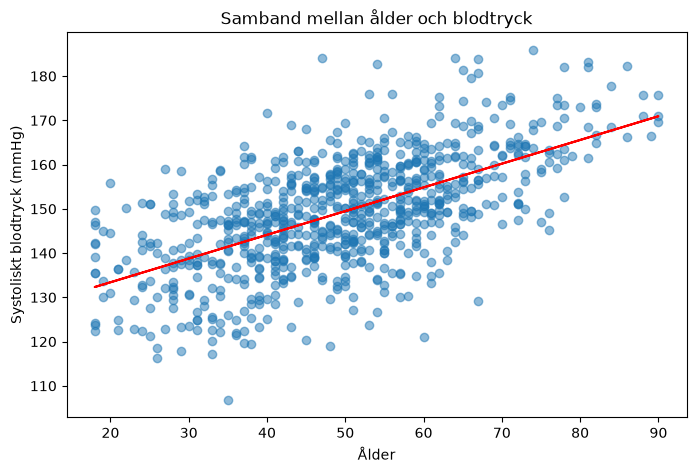

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(df["age"], df["systolic_bp"], alpha=0.5)

plt.plot(df["age"], modell.predict(X), color="red")

plt.xlabel("Ålder")
plt.ylabel("Systoliskt blodtryck (mmHg)")
plt.title("Samband mellan ålder och blodtryck")

plt.show()

 Tolkning av diagrammet

Diagrammet visar sambandet mellan ålder och systoliskt blodtryck.

De blå punkterna visar deltagarnas värden och den röda linjen visar den linjära regressionen.

Jag ser att blodtrycket oftast ökar med åldern. Men punkterna är utspridda, vilket betyder att även andra faktorer kan påverka blodtrycket.

In [7]:
X2 = df[["age", "weight"]]
y2 = df["systolic_bp"]

modell2 = LinearRegression()
modell2.fit(X2, y2)

print("Ålder:", round(modell2.coef_[0], 2))
print("Vikt:", round(modell2.coef_[1], 2))
print("R²:", round(modell2.score(X2, y2), 2))

Ålder: 0.54
Vikt: 0.18
R²: 0.41


 Tolkning av multipel linjär regression

Jag använde multipel linjär regression för att undersöka hur ålder och vikt hänger ihop med systoliskt blodtryck.

Resultatet visar att blodtrycket ökar med ungefär 0,54 mmHg för varje extra år, om vikten är densamma.

För varje extra kilo ökar det förväntade blodtrycket med ungefär 0,18 mmHg, om åldern är densamma.

R² blev 0,41. Det betyder att modellen förklarar ungefär 41 % av variationen i blodtrycket.

Den första modellen med bara ålder hade R² = 0,37. När jag lade till vikt blev resultatet lite bättre.

Jag valde denna metod eftersom jag ville undersöka två faktorer samtidigt. Resultatet visar samband, men det betyder inte att ålder och vikt ensamma orsakar högt blodtryck.

 Metodval och källor

Jag använde pandas för att läsa och analysera data. Jag valde linjär regression för att undersöka sambandet mellan ålder och blodtryck. Sedan använde jag multipel linjär regression för att undersöka både ålder och vikt samtidigt.

Jag använde scikit-learn för regressionen och Matplotlib för att visa resultatet i ett diagram.


 Källor

- [pandas dokumentation](https://pandas.pydata.org/docs/)
- [scikit-learn – LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
- [Matplotlib dokumentation](https://matplotlib.org/stable/)


